## San Diego VMT Study

# Import Libraries

In [3]:
import numpy as np # Core numerical and array operations
import pandas as pd # Data table and analysis operations
import matplotlib.pyplot as plt # Plotting; syntax and appearance similar to Matlab
import pathlib # file handling robust to switching between Mac, PC, and Linux platforms
import geopandas as gpd # GIS functionality added to pandas. We will use lightly here to make a map.
import seaborn as sns # use this for correlation matrix for top-level feature selection analysis

In [4]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


# VMT Data Import

In [5]:
cwd = pathlib.Path().cwd()
cwd


WindowsPath('C:/Users/chris/OneDrive/Documents/GitHub/The858')

In [6]:
inputdir = cwd / 'inputdata' # pathlib abstracts the Mac vs. PC syntax difference using '/' not as a string
inputdir

WindowsPath('C:/Users/chris/OneDrive/Documents/GitHub/The858/inputdata')

In [7]:
datafile = inputdir / 'CARB-UCB-CA_VMT_Estimates_DataVintage_Oct2025_PRELIMINARY_FOR_STUDENT_USE.csv'


# View Data

In [8]:
data = pd.read_csv(datafile)
data.head(10)


,1,GEOID,RetDens_bg_z,DensBusStops_one_z,NetLoadDens_GF18_two_z,JobsWi45_transit_to_car_ratio,JobsWithin45_Car_z,StreetDens_GF18_two_z,cbsa_IE,cbsa_LA_OC,VMT_state,VMT_state_trunc,VMT_diff_state,VMT_CBSA,VMT_CBSA_trunc,VMT_diff_CBSA
0,2,60259400003,0.130,0.362,3.634,-0.190,0.735,0.3702,0.0,0.0000,5.040,5.040,6.370,5.040,5.040,3.273
1,3,60250108002,0.133,0.362,3.500,0.000,0.698,0.4617,0.0,0.0000,5.155,5.155,6.486,5.155,5.155,3.388
2,4,60250108001,0.133,0.362,3.511,0.000,0.692,0.4865,0.0,0.0000,5.185,5.185,6.515,5.185,5.185,3.418
3,5,60250111003,0.133,0.362,3.513,0.000,0.681,0.4965,0.0,0.0000,5.185,5.185,6.516,5.185,5.185,3.418
4,6,60730100132,-0.025,0.042,-2.598,-0.764,-0.048,-0.2850,0.0,0.0000,-3.677,-3.677,-2.346,-3.677,-3.677,-2.384
5,7,60373104003,-0.115,-0.090,-6.003,-0.839,-2.742,-0.0708,0.0,2.4049,-7.456,-7.456,-6.125,-9.861,-9.861,-3.887
6,8,60310007014,0.124,0.362,0.172,-0.354,0.567,-0.0103,0.0,0.0000,0.860,0.860,2.191,0.860,0.860,-0.968
7,9,60310003002,0.132,0.362,0.889,0.000,0.711,-0.1259,0.0,0.0000,1.968,1.968,3.298,1.968,1.968,0.140
8,10,60310002002,0.133,0.362,3.701,0.000,0.699,0.4480,0.0,0.0000,5.343,5.343,6.674,5.343,5.343,3.515
9,11,60590865023,0.133,0.362,-3.051,-0.542,-3.067,-0.4123,0.0,2.4049,-4.172,-4.172,-2.841,-6.577,-6.577,-0.603


# Clean GEOID Column

In [9]:
data['GEOID'] = data['GEOID'].map(str).str.zfill(12)
data.head()

,1,GEOID,RetDens_bg_z,DensBusStops_one_z,NetLoadDens_GF18_two_z,JobsWi45_transit_to_car_ratio,JobsWithin45_Car_z,StreetDens_GF18_two_z,cbsa_IE,cbsa_LA_OC,VMT_state,VMT_state_trunc,VMT_diff_state,VMT_CBSA,VMT_CBSA_trunc,VMT_diff_CBSA
0,2,060259400003,0.130,0.362,3.634,-0.190,0.735,0.3702,0.0,0.0,5.040,5.040,6.370,5.040,5.040,3.273
1,3,060250108002,0.133,0.362,3.500,0.000,0.698,0.4617,0.0,0.0,5.155,5.155,6.486,5.155,5.155,3.388
2,4,060250108001,0.133,0.362,3.511,0.000,0.692,0.4865,0.0,0.0,5.185,5.185,6.515,5.185,5.185,3.418
3,5,060250111003,0.133,0.362,3.513,0.000,0.681,0.4965,0.0,0.0,5.185,5.185,6.516,5.185,5.185,3.418
4,6,060730100132,-0.025,0.042,-2.598,-0.764,-0.048,-0.2850,0.0,0.0,-3.677,-3.677,-2.346,-3.677,-3.677,-2.384


In [10]:
data_cleaned = data.set_index('GEOID')[['VMT_diff_state']]
data_cleaned.head()

,VMT_diff_state
GEOID,
060259400003,6.370
060250108002,6.486
060250108001,6.515
060250111003,6.516
060730100132,-2.346


In [11]:
data_cleaned.describe()

,VMT_diff_state
count,23190.000000
mean,-0.256459
std,4.770563
min,-14.135000
25%,-2.704750
50%,0.303000
75%,2.936000
max,10.676000


# Calculate State-wide VMT Baseline using EMFAC (LDA, LDT1, LDT2, MCY)

In [12]:
VMT_state = 716/39.5 # sum of VMT from downloaded spreadsheet divided by California population

In [13]:
vmt = data_cleaned + VMT_state # important distinction between EMFAC (VMT_state), which is VMT driven within the boundaries of the state 
# and neighborhood data which are miles driven by residents of the state (data_clearned)

vmt = vmt.rename({'VMT_diff_state': 'VMTpc'}, axis=1)
vmt.describe()

,VMTpc
count,23190.000000
mean,17.870123
std,4.770563
min,3.991582
25%,15.421832
50%,18.429582
75%,21.062582
max,28.802582


# Visualization

In [14]:
ca_cbg_shapefile_path = inputdir / 'cb_2019_06_bg_500k' / 'cb_2019_06_bg_500k.shp'
gdf = gpd.read_file(ca_cbg_shapefile_path) # Basic geopandas read; it will figure out it is a shapefile format.
gdf.head() # dataframe functions are inherited by geodataframes, in addition to geodataframe specific functions. 

,STATEFP,COUNTYFP,TRACTCE,BLKGRPCE,AFFGEOID,GEOID,NAME,LSAD,ALAND,AWATER,geometry
0,06,037,800408,1,1500000US060378004081,060378004081,1,BG,2792751,1500447,"POLYGON ((-118.78754 34.02718, -118.78607 34.0..."
1,06,041,124200,4,1500000US060411242004,060411242004,4,BG,2259455,973726,"POLYGON ((-122.48698 37.89918, -122.48416 37.9..."
2,06,059,062619,4,1500000US060590626194,060590626194,4,BG,369794,343273,"POLYGON ((-117.77753 33.53639, -117.77558 33.5..."
3,06,051,000101,1,1500000US060510001011,060510001011,1,BG,2978150540,1148631,"POLYGON ((-118.94597 37.77522, -118.94348 37.7..."
4,06,093,000200,1,1500000US060930002001,060930002001,1,BG,1300052761,72751421,"POLYGON ((-122.25174 41.75805, -122.24754 41.7..."


<Axes: >

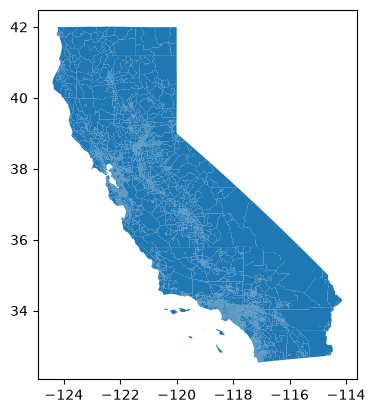

In [15]:
gdf.plot()

In [16]:
gdf['ALAND'].sum() / 1e6 # convert m^2 to km^2

np.float64(403660.088482)

# Extract San Diego Data

In [17]:
# San Diego FIPS code = 073
sd_shape = gdf[gdf['COUNTYFP'] == '073']
len(gdf)

23196

<Axes: >

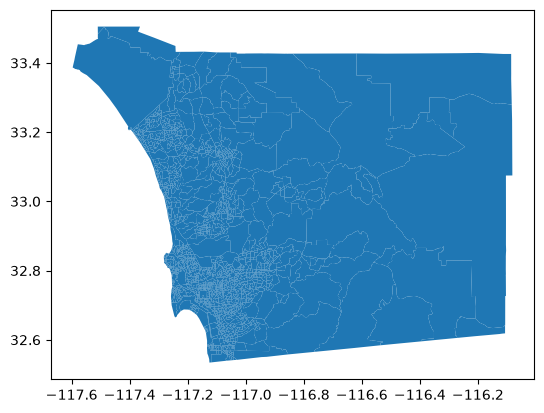

In [18]:
sd_shape.plot()

# Merge

In [19]:
merged = sd_shape.merge(vmt, left_on='GEOID', right_index=True, how='inner')
len(merged)

1794

In [20]:
merged.head()

,STATEFP,COUNTYFP,TRACTCE,BLKGRPCE,AFFGEOID,GEOID,NAME,LSAD,ALAND,AWATER,geometry,VMTpc
27,06,073,003305,1,1500000US060730033051,060730033051,1,BG,441435,0,"POLYGON ((-117.09519 32.70412, -117.09492 32.7...",15.308582
36,06,073,008347,2,1500000US060730083472,060730083472,2,BG,408199,0,"POLYGON ((-117.15141 32.92595, -117.15186 32.9...",17.900582
39,06,073,008006,3,1500000US060730080063,060730080063,3,BG,109500,0,"POLYGON ((-117.26217 32.80799, -117.25928 32.8...",17.273582
85,06,073,015801,1,1500000US060730158011,060730158011,1,BG,430195,0,"POLYGON ((-116.96235 32.79911, -116.9581 32.79...",15.260582
94,06,073,011601,2,1500000US060730116012,060730116012,2,BG,222974,0,"POLYGON ((-117.10356 32.6672, -117.09535 32.66...",14.350582


In [21]:
sd_vmt = merged.set_index('GEOID')[['VMTpc', 'geometry']]
sd_vmt.head()

,VMTpc,geometry
GEOID,,
060730033051,15.308582,"POLYGON ((-117.09519 32.70412, -117.09492 32.7..."
060730083472,17.900582,"POLYGON ((-117.15141 32.92595, -117.15186 32.9..."
060730080063,17.273582,"POLYGON ((-117.26217 32.80799, -117.25928 32.8..."
060730158011,15.260582,"POLYGON ((-116.96235 32.79911, -116.9581 32.79..."
060730116012,14.350582,"POLYGON ((-117.10356 32.6672, -117.09535 32.66..."


# VMT Map

<Axes: >

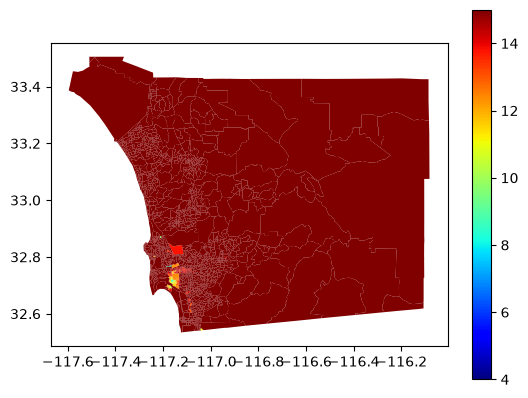

In [22]:
sd_vmt.plot(column='VMTpc', legend=True, cmap='jet', vmin=4, vmax=15)


# Merge with ACS population and housing Data

In [23]:
ca_pop_data_file = inputdir / 'ACSDT5Y2019.B01003_2026-09-27T122429' / 'ACSDT5Y2019.B01003-Data.csv'
ca_pop_data = pd.read_csv(ca_pop_data_file)
ca_pop_data.head()

,GEO_ID,NAME,B01003_001E,B01003_001M,Unnamed: 4
0,Geography,Geographic Area Name,Estimate!!Total,Margin of Error!!Total,NaN
1,0400000US06,California,39283497,*****,NaN
2,0500000US06073,"San Diego County, California",3316073,*****,NaN


In [24]:
ca_pop_data = pd.read_csv(ca_pop_data_file, skiprows=[1])
ca_pop_data.head()

,GEO_ID,NAME,B01003_001E,B01003_001M,Unnamed: 4
0,0400000US06,California,39283497,*****,NaN
1,0500000US06073,"San Diego County, California",3316073,*****,NaN


Trim Geoid 15000000US Prefix

In [25]:
ca_pop_data['GEOID'] = ca_pop_data['GEO_ID'].map(lambda x: x[9:]) # remove first nine characters
ca_pop_data.head()

,GEO_ID,NAME,B01003_001E,B01003_001M,Unnamed: 4,GEOID
0,0400000US06,California,39283497,*****,NaN,06
1,0500000US06073,"San Diego County, California",3316073,*****,NaN,06073


Set GEOID as Index, rename column of interest, and drop remainder

In [26]:
pop = ca_pop_data.set_index('GEOID')[['B01003_001E']].rename({'B01003_001E': 'Population'}, axis=1)
pop.head()

,Population
GEOID,
06,39283497
06073,3316073


Function to combine Housing + Population Data 

In [27]:
def read_census_table(table_name, filename, variable_name,
                      skiprows=[1], inputdir=inputdir, geo_in_name='GEO_ID', geo_out_name='GEOID', trim_length=9,
                      column_suffix='_001E'):

    # Read data
    data = pd.read_csv(inputdir / filename, skiprows=skiprows)

    # Trim leading FIPS code strings.
    data[geo_out_name] = data[geo_in_name].map(lambda x: x[trim_length:])

    # Set index, rename column to something more readable, and drop other columns.
    column_name = table_name + column_suffix # Using '+' for a string concatenates.
    data_out = data.set_index(geo_out_name)[[column_name]].rename({column_name: variable_name}, axis=1)
    
    return data_out

In [28]:
read_census_table('B01003', 'ACSDT5Y2019.B01003_2026-09-27T122429/ACSDT5Y2019.B01003-Data.csv', 'Population').sum()

Population    42599570
dtype: int64

In [29]:
housing_units = read_census_table('B25001', 'ACSDT5Y2019.B25001_2026-09-27T131118/ACSDT5Y2019.B25001-Data.csv', 'Housing Units')
housing_units.head()

,Housing Units
GEOID,
,137428986


In [30]:
housing_units.sum()

Housing Units    137428986
dtype: int64

Merge VMT, Population, Housing Units

In [31]:
vmt_merged = vmt.merge(pop, left_index=True, right_index=True, how='inner')
vmt_merged = vmt_merged.merge(housing_units, left_index=True, right_index=True, how='inner')
vmt_merged.head()

,VMTpc,Population,Housing Units
GEOID,,,


In [32]:
len(vmt_merged)

0

# Statistics

In [33]:
statewide_mean_vmt_calc = (vmt_merged['VMTpc'] * vmt_merged['Population']).sum() / vmt_merged['Population'].sum()
statewide_mean_vmt_calc


C:\Users\chris\AppData\Local\Temp\ipykernel_49680\2821086122.py:1: RuntimeWarning: invalid value encountered in scalar divide
  statewide_mean_vmt_calc = (vmt_merged['VMTpc'] * vmt_merged['Population']).sum() / vmt_merged['Population'].sum()


np.float64(nan)

In [34]:
statewide_mean_vmt_calc - VMT_state

np.float64(nan)

Histogram

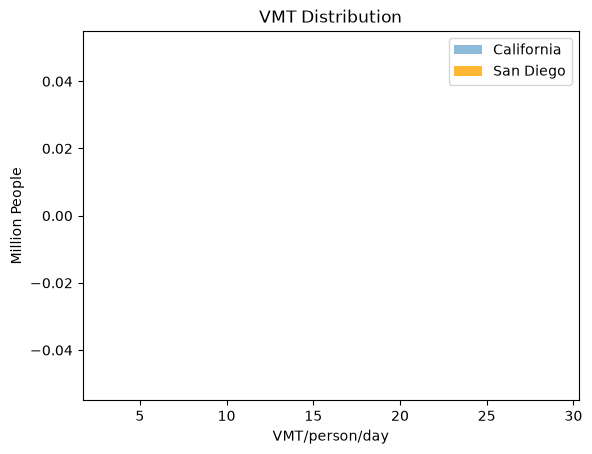

In [35]:
# Plot the statewide data
plt.hist(vmt_merged['VMTpc'], weights=vmt_merged['Population'] / 1e6, bins=np.arange(3, 30), alpha=0.5, label='California')
# Set bins to be 1 VMT from 3 to 30, use millions of people for plotting convenience.

# Filter San Diego County (state FIPS 06, county FIPS 073)
sd_vmt_merged = vmt_merged[vmt_merged.index.str.startswith('06073')]
plt.hist(sd_vmt_merged['VMTpc'], weights=sd_vmt_merged['Population'] / 1e6, bins=np.arange(3, 30), color='orange', alpha=0.8, label='San Diego')

plt.xlabel('VMT/person/day')
plt.ylabel('Million People')
plt.title('VMT Distribution')
plt.legend()



In [36]:
vmt_merged = vmt_merged.merge(gdf[['GEOID', 'ALAND']], left_index=True, right_on='GEOID', how='inner')
vmt_merged = vmt_merged.set_index('GEOID')
vmt_merged.head()

,VMTpc,Population,Housing Units,ALAND
GEOID,,,,


In [37]:
vmt_merged['Population Density'] = vmt_merged['Population'] / vmt_merged['ALAND'] * 1e6 * 1.61**2
# people/m^2 * m^2/km^2 * km^2/mi^2 = people/mi^2.
vmt_merged.describe()

,VMTpc,Population,Housing Units,ALAND,Population Density
count,0.0,0.0,0.0,0.0,0.0
mean,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN
max,NaN,NaN,NaN,NaN,NaN


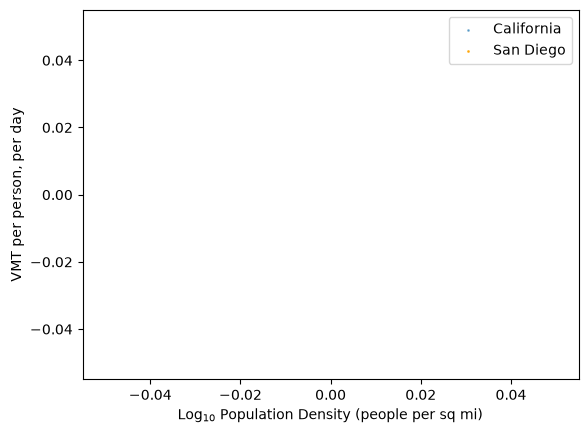

In [38]:
# Scatterplot
# First filter to rows with > 0 pop density. We'll use > 1 to avoid small floating point issues.
vmt_subset = vmt_merged[vmt_merged['Population Density'] > 1]

# Plot the statewide data
plt.scatter(np.log10(vmt_subset['Population Density']), vmt_subset['VMTpc'], s=1, alpha=0.5, label='California')

# San Diego data overlaid
sd_vmt_subset = vmt_subset[vmt_subset.index.str.startswith('06073')]
plt.scatter(np.log10(sd_vmt_subset['Population Density']), sd_vmt_subset['VMTpc'], s=1, color='orange', alpha=0.8, label='San Diego')

plt.ylabel('VMT per person, per day')
plt.xlabel('Log$_{10}$ Population Density (people per sq mi)')
plt.legend()


In [39]:
sd_vmt = sd_vmt.merge(pop, left_index=True, right_index=True, how='inner')
sd_vmt = sd_vmt.merge(housing_units,left_index=True, right_index=True, how='inner') 


In [40]:
sd_vmt.head()

,VMTpc,geometry,Population,Housing Units
GEOID,,,,


In [41]:
sd_popmean_vmt = (sd_vmt['VMTpc'] * sd_vmt['Population']).sum() / sd_vmt['Population'].sum()
sd_popmean_vmt

C:\Users\chris\AppData\Local\Temp\ipykernel_49680\180047384.py:1: RuntimeWarning: invalid value encountered in scalar divide
  sd_popmean_vmt = (sd_vmt['VMTpc'] * sd_vmt['Population']).sum() / sd_vmt['Population'].sum()


np.float64(nan)

In [42]:
sd_popmean_vmt - statewide_mean_vmt_calc

np.float64(nan)

In [43]:
deciles = np.arange(0, 1.1, 0.1)
sd_vmt_deciles = np.quantile(sd_vmt['VMTpc'], deciles, weights=sd_vmt['Population'],
                            method='inverted_cdf')

# To make it easier to look at, let's make a dictionary using "Dictionary Comprehension" (e.g. https://www.geeksforgeeks.org/python/python-dictionary-comprehension/).
sd_vmt_deciles = {round(deciles[x], 1): round(sd_vmt_deciles[x], 1) for x in range(len(deciles))}
sd_vmt_deciles

IndexError: index -1 is out of bounds for axis 0 with size 0

# City of San Diego VMT Analysis

This section isolates Census block groups associated with the **City of San Diego** and compares their resident VMT patterns with San Diego County overall and the remainder of the county.

To keep the comparison consistent with the County analysis above, this section uses the same 2019 block-group VMT, ACS population, housing, land-area, and population-density data already loaded in `vmt_merged`.

**Geographic method:** City membership is approximated by assigning each 2019 Census block group to the City of San Diego when the block group's representative point falls inside the 2019 Census TIGER/Line City boundary. This preserves whole block groups so the geography remains compatible with the block-group VMT data.

In [ ]:
# Download/load the 2019 Census TIGER/Line California Places boundary if needed.
import zipfile
import urllib.request

city_place_url = (
    "https://www2.census.gov/geo/tiger/TIGER2019/PLACE/"
    "tl_2019_06_place.zip"
)

city_place_zip = inputdir / "tl_2019_06_place.zip"
city_place_folder = inputdir / "tl_2019_06_place"
city_place_shp = city_place_folder / "tl_2019_06_place.shp"

if not city_place_zip.exists():
    urllib.request.urlretrieve(city_place_url, city_place_zip)

if not city_place_shp.exists():
    city_place_folder.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(city_place_zip, "r") as zip_ref:
        zip_ref.extractall(city_place_folder)

ca_places_2019 = gpd.read_file(city_place_shp)

print("California places loaded:", len(ca_places_2019))

In [ ]:
# City of San Diego Census place code = 66000
sd_city_boundary = ca_places_2019[
    ca_places_2019["PLACEFP"] == "66000"
].copy()

print("City boundary rows:", len(sd_city_boundary))
display(sd_city_boundary[["NAME", "PLACEFP", "GEOID"]])

In [ ]:
# Assign San Diego County block groups to the City using representative points.
# EPSG:3310 is the California Albers projected CRS.
sd_bg_citycheck = sd_shape[["GEOID", "geometry"]].copy().to_crs(epsg=3310)
sd_city_boundary_proj = sd_city_boundary.to_crs(epsg=3310)

sd_bg_citycheck["rep_point"] = (
    sd_bg_citycheck.geometry.representative_point()
)

sd_city_geometry = sd_city_boundary_proj.geometry.iloc[0]

sd_bg_citycheck["in_sd_city"] = (
    sd_bg_citycheck["rep_point"].within(sd_city_geometry)
)

sd_city_geoids = sd_bg_citycheck.loc[
    sd_bg_citycheck["in_sd_city"], "GEOID"
].astype(str)

print("San Diego County block groups:", len(sd_bg_citycheck))
print("Block groups assigned to City of San Diego:", len(sd_city_geoids))

In [ ]:
# Build comparable City, rest-of-County, and County-wide VMT datasets.
sd_county_compare = vmt_merged[
    vmt_merged.index.str.startswith("06073")
].copy()

sd_city_compare = sd_county_compare[
    sd_county_compare.index.isin(sd_city_geoids)
].copy()

sd_rest_county_compare = sd_county_compare[
    ~sd_county_compare.index.isin(sd_city_geoids)
].copy()

print("County rows:", len(sd_county_compare))
print("City rows:", len(sd_city_compare))
print("Rest of County rows:", len(sd_rest_county_compare))

In [ ]:
def population_weighted_vmt(df):
    valid = df[["VMTpc", "Population"]].dropna().copy()
    valid = valid[valid["Population"] > 0]
    return np.average(
        valid["VMTpc"],
        weights=valid["Population"]
    )

city_mean_vmt = population_weighted_vmt(sd_city_compare)
county_mean_vmt = population_weighted_vmt(sd_county_compare)
rest_county_mean_vmt = population_weighted_vmt(sd_rest_county_compare)

print("City of San Diego:", round(city_mean_vmt, 2))
print("San Diego County overall:", round(county_mean_vmt, 2))
print("Rest of San Diego County:", round(rest_county_mean_vmt, 2))

In [ ]:
city_county_summary = pd.DataFrame({
    "Geography": [
        "City of San Diego",
        "Rest of San Diego County",
        "San Diego County Overall"
    ],
    "Population": [
        sd_city_compare["Population"].sum(),
        sd_rest_county_compare["Population"].sum(),
        sd_county_compare["Population"].sum()
    ],
    "Housing Units": [
        sd_city_compare["Housing Units"].sum(),
        sd_rest_county_compare["Housing Units"].sum(),
        sd_county_compare["Housing Units"].sum()
    ],
    "VMT per Person per Day": [
        city_mean_vmt,
        rest_county_mean_vmt,
        county_mean_vmt
    ]
})

city_county_summary

In [ ]:
# Compare population-weighted resident VMT across the three geographies.
ax = city_county_summary.plot(
    x="Geography",
    y="VMT per Person per Day",
    kind="bar",
    figsize=(9, 5),
    legend=False,
    rot=10
)

ax.set_ylabel("VMT per Person per Day")
ax.set_xlabel("")
ax.set_title("Resident VMT: City of San Diego vs. San Diego County")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3)

plt.tight_layout()
plt.show()

In [ ]:
# Map City and County VMT using the same color scale.
sd_county_vmt_map = sd_shape[["GEOID", "geometry"]].merge(
    sd_county_compare[["VMTpc"]],
    left_on="GEOID",
    right_index=True,
    how="inner"
)

sd_city_vmt_map = sd_shape[
    sd_shape["GEOID"].isin(sd_city_geoids)
][["GEOID", "geometry"]].merge(
    sd_city_compare[["VMTpc"]],
    left_on="GEOID",
    right_index=True,
    how="inner"
)

vmt_map_min = sd_county_compare["VMTpc"].quantile(0.05)
vmt_map_max = sd_county_compare["VMTpc"].quantile(0.95)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

sd_county_vmt_map.plot(
    column="VMTpc",
    cmap="viridis",
    vmin=vmt_map_min,
    vmax=vmt_map_max,
    legend=True,
    ax=axes[0]
)
axes[0].set_title("San Diego County VMT per Person")
axes[0].set_axis_off()

sd_city_vmt_map.plot(
    column="VMTpc",
    cmap="viridis",
    vmin=vmt_map_min,
    vmax=vmt_map_max,
    legend=True,
    ax=axes[1]
)
axes[1].set_title("City of San Diego VMT per Person")
axes[1].set_axis_off()

plt.tight_layout()
plt.show()

In [ ]:
# Population-weighted VMT distributions for the City and remainder of the County.
bins = np.arange(
    np.floor(sd_county_compare["VMTpc"].min()),
    np.ceil(sd_county_compare["VMTpc"].max()) + 1,
    1
)

city_weights = (
    sd_city_compare["Population"]
    / sd_city_compare["Population"].sum()
    * 100
)

rest_county_weights = (
    sd_rest_county_compare["Population"]
    / sd_rest_county_compare["Population"].sum()
    * 100
)

plt.figure(figsize=(9, 6))

plt.hist(
    sd_city_compare["VMTpc"],
    bins=bins,
    weights=city_weights,
    alpha=0.6,
    label="City of San Diego"
)

plt.hist(
    sd_rest_county_compare["VMTpc"],
    bins=bins,
    weights=rest_county_weights,
    alpha=0.5,
    label="Rest of San Diego County"
)

plt.xlabel("VMT per Person per Day")
plt.ylabel("Percent of Population")
plt.title("Resident VMT Distribution: City vs. Rest of County")
plt.legend()
plt.show()

In [ ]:
# Compare population density and VMT for City block groups versus the rest of the County.
city_density = sd_city_compare[
    sd_city_compare["Population Density"] > 1
].copy()

rest_density = sd_rest_county_compare[
    sd_rest_county_compare["Population Density"] > 1
].copy()

plt.figure(figsize=(9, 6))

plt.scatter(
    np.log10(city_density["Population Density"]),
    city_density["VMTpc"],
    s=8,
    alpha=0.4,
    label="City of San Diego"
)

plt.scatter(
    np.log10(rest_density["Population Density"]),
    rest_density["VMTpc"],
    s=8,
    alpha=0.3,
    label="Rest of San Diego County"
)

plt.xlabel("Log$_{10}$ Population Density (people per sq mi)")
plt.ylabel("VMT per Person per Day")
plt.title("Population Density and Resident VMT")
plt.legend()
plt.show()

city_density_corr = np.corrcoef(
    np.log10(city_density["Population Density"]),
    city_density["VMTpc"]
)[0, 1]

rest_density_corr = np.corrcoef(
    np.log10(rest_density["Population Density"]),
    rest_density["VMTpc"]
)[0, 1]

print("City correlation:", round(city_density_corr, 3))
print("Rest of County correlation:", round(rest_density_corr, 3))

# VMT and CalEnviroScreen 5.0

This section examines how resident VMT aligns with **CalEnviroScreen 5.0 (CES 5.0)** cumulative environmental-burden scores.

The VMT dataset uses 2019 Census block groups, while CES 5.0 uses newer Census tract geography. To avoid an invalid GEOID join across vintages, each VMT block group is spatially assigned to the CES tract containing its representative point.

`CIscoreP` is used as the statewide CalEnviroScreen percentile. For this exploratory analysis, tracts at or above the 75th percentile are labeled **Top 25% CES / high-burden tracts**.

> **Important:** `CIscoreP >= 75` is a useful CES 5.0 high-burden indicator, but it is not identical to the full official SB 535 disadvantaged-community designation, which includes additional designation rules.

In [ ]:
# Locate and load the CalEnviroScreen 5.0 shapefile from inputdata.
ces_folder = inputdir / "CalEnviroScreen5"
preferred_ces_shp = ces_folder / "CES5_final_shapefile.shp"

if preferred_ces_shp.exists():
    ces_shp = preferred_ces_shp
else:
    ces_shapefiles = list(ces_folder.rglob("*.shp"))
    if len(ces_shapefiles) == 0:
        raise FileNotFoundError(
            "No CalEnviroScreen 5.0 shapefile was found under "
            f"{ces_folder}. Add the extracted CES 5.0 shapefile there first."
        )
    ces_shp = ces_shapefiles[0]

ces5 = gpd.read_file(ces_shp)

print("CES 5.0 shapefile:", ces_shp)
print("California CES tracts:", len(ces5))

In [ ]:
# Clean tract IDs and CES percentile fields, then isolate San Diego County.
ces5_clean = ces5.copy()

ces5_clean["tract_geoid"] = (
    pd.to_numeric(
        ces5_clean["tract"],
        errors="coerce"
    )
    .astype("Int64")
    .astype(str)
    .str.zfill(11)
)

for col in [
    "CIscore",
    "CIscoreP",
    "PollutionP",
    "PopCharP"
]:
    ces5_clean[col] = pd.to_numeric(
        ces5_clean[col],
        errors="coerce"
    )

ces5_sd = ces5_clean[
    ces5_clean["tract_geoid"].str.startswith("06073")
].copy()

print("San Diego County CES tracts:", len(ces5_sd))

display(
    ces5_sd[
        [
            "tract_geoid",
            "county",
            "CIscore",
            "CIscoreP",
            "PollutionP",
            "PopCharP"
        ]
    ].head()
)

In [ ]:
# Join each San Diego VMT block group to the CES 5.0 tract containing its representative point.
sd_vmt_ces = sd_shape[
    ["GEOID", "geometry"]
].merge(
    sd_county_compare[
        ["VMTpc", "Population"]
    ],
    left_on="GEOID",
    right_index=True,
    how="inner"
)

sd_vmt_ces["in_sd_city"] = (
    sd_vmt_ces["GEOID"].isin(sd_city_geoids)
)

sd_vmt_ces = sd_vmt_ces.to_crs(ces5_sd.crs)

sd_vmt_points = sd_vmt_ces.copy()
sd_vmt_points["geometry"] = (
    sd_vmt_points.geometry.representative_point()
)

bg_ces_join = gpd.sjoin(
    sd_vmt_points,
    ces5_sd[
        [
            "tract_geoid",
            "CIscore",
            "CIscoreP",
            "PollutionP",
            "PopCharP",
            "geometry"
        ]
    ],
    how="left",
    predicate="within"
)

print(
    "Matched VMT block groups:",
    bg_ces_join["tract_geoid"].notna().sum()
)
print("Total San Diego VMT block groups:", len(bg_ces_join))
print(
    "Unmatched:",
    bg_ces_join["tract_geoid"].isna().sum()
)

In [ ]:
# Create a top-25% CES high-burden indicator and inspect the City subset.
bg_ces_join["CES_top25"] = (
    bg_ces_join["CIscoreP"] >= 75
)

city_ces_vmt = bg_ces_join[
    bg_ces_join["in_sd_city"]
].copy()

print("City VMT block groups:", len(city_ces_vmt))
print(
    "City block groups in top-25% CES tracts:",
    city_ces_vmt["CES_top25"].sum()
)

In [ ]:
# Compare population-weighted VMT in top-25% CES tracts versus other communities.
county_top25 = bg_ces_join[
    bg_ces_join["CES_top25"]
].copy()

county_other = bg_ces_join[
    ~bg_ces_join["CES_top25"]
].copy()

city_top25 = city_ces_vmt[
    city_ces_vmt["CES_top25"]
].copy()

city_other = city_ces_vmt[
    ~city_ces_vmt["CES_top25"]
].copy()

county_top25_vmt = population_weighted_vmt(county_top25)
county_other_vmt = population_weighted_vmt(county_other)
city_top25_vmt = population_weighted_vmt(city_top25)
city_other_vmt = population_weighted_vmt(city_other)

print("San Diego County - Top 25% CES:", round(county_top25_vmt, 2))
print("San Diego County - Other communities:", round(county_other_vmt, 2))
print()
print("City of San Diego - Top 25% CES:", round(city_top25_vmt, 2))
print("City of San Diego - Other communities:", round(city_other_vmt, 2))

In [ ]:
ces_vmt_summary = pd.DataFrame({
    "Geography": [
        "San Diego County",
        "San Diego County",
        "City of San Diego",
        "City of San Diego"
    ],
    "Community Type": [
        "Top 25% CES",
        "Other Communities",
        "Top 25% CES",
        "Other Communities"
    ],
    "VMT per Person per Day": [
        county_top25_vmt,
        county_other_vmt,
        city_top25_vmt,
        city_other_vmt
    ]
})

ces_vmt_summary

In [ ]:
# Visualize CES high-burden versus other communities for County and City.
ces_vmt_pivot = ces_vmt_summary.pivot(
    index="Geography",
    columns="Community Type",
    values="VMT per Person per Day"
)

ax = ces_vmt_pivot.plot(
    kind="bar",
    figsize=(9, 6),
    rot=0
)

ax.set_ylabel("VMT per Person per Day")
ax.set_xlabel("")
ax.set_title("Resident VMT by CalEnviroScreen 5.0 Burden")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3)

plt.tight_layout()
plt.show()

In [ ]:
# Overlay top-25% CES tract boundaries on the County VMT map.
ces_top25_sd = ces5_sd[
    ces5_sd["CIscoreP"] >= 75
].copy()

fig, ax = plt.subplots(figsize=(11, 10))

sd_county_vmt_map.to_crs(
    ces5_sd.crs
).plot(
    column="VMTpc",
    cmap="viridis",
    vmin=vmt_map_min,
    vmax=vmt_map_max,
    legend=True,
    ax=ax
)

# Thin outlines = top-25% CES tracts
ces_top25_sd.boundary.plot(
    ax=ax,
    linewidth=1.2
)

# Thicker outline = City of San Diego boundary
sd_city_boundary.to_crs(
    ces5_sd.crs
).boundary.plot(
    ax=ax,
    linewidth=2.5
)

ax.set_title(
    "San Diego County Resident VMT with Top-25% "
    "CalEnviroScreen 5.0 Tracts"
)
ax.set_axis_off()

plt.show()

In [ ]:
# Aggregate block-group VMT to CES tract level for a continuous CES percentile comparison.
tract_analysis = bg_ces_join[
    [
        "tract_geoid",
        "VMTpc",
        "Population",
        "CIscore",
        "CIscoreP",
        "in_sd_city"
    ]
].dropna().copy()

tract_analysis["weighted_vmt"] = (
    tract_analysis["VMTpc"]
    * tract_analysis["Population"]
)

tract_summary = (
    tract_analysis
    .groupby("tract_geoid")
    .agg(
        weighted_vmt_sum=("weighted_vmt", "sum"),
        population=("Population", "sum"),
        CIscore=("CIscore", "first"),
        CIscoreP=("CIscoreP", "first"),
        in_sd_city=("in_sd_city", "max")
    )
)

tract_summary["VMTpc"] = (
    tract_summary["weighted_vmt_sum"]
    / tract_summary["population"]
)

print("CES tracts represented in VMT analysis:", len(tract_summary))
display(tract_summary.head())

In [ ]:
# Continuous relationship between CES percentile and resident VMT.
plt.figure(figsize=(9, 6))

plt.scatter(
    tract_summary["CIscoreP"],
    tract_summary["VMTpc"],
    alpha=0.5
)

plt.xlabel("CalEnviroScreen 5.0 Percentile")
plt.ylabel("VMT per Person per Day")
plt.title("Resident VMT and Cumulative Environmental Burden")
plt.show()

ces_vmt_corr = np.corrcoef(
    tract_summary["CIscoreP"],
    tract_summary["VMTpc"]
)[0, 1]

print(
    "CES percentile / VMT correlation:",
    round(ces_vmt_corr, 3)
)

## Interpretation notes for the group

Use the outputs above to distinguish between **resident travel generation** and **environmental burden**. A high CalEnviroScreen percentile does not necessarily imply that residents of that tract generate more VMT; communities can experience transportation pollution and cumulative burdens from highways, freight activity, industrial land uses, and through-traffic that are not represented by resident VMT alone.

The City/County comparison, CES high-burden comparison, and continuous CES-percentile analysis should therefore be interpreted together rather than as interchangeable measures.

# DP03 Economic Characteristics of San Diego County

From US Census Bureau DP03 (Economic Characteristics)
- 0004E (Total Employed)
- 0009PE Unemployment Rate
- 0062E Median Household Income
- 0119PE Percent of families below the poverty level
- 0019E Drove alone
- 0020E Carpooled
- 0021E Public Transportation (excludes rideshare)
- 0024E Worked from home
- 0025E Mean Travel time to work (in minutes)

In [ ]:
# target columns / when you download a ZIP file from the US census buereau, there is a file in there called -'column-metadata.csv' and that's how you can map the column "codes" to new column names so it's easiet to filter, etc
columns_to_keep_dp03 = { # when you use {} it's called a 'dictionary' and you map key:value pairs to each other. If you download a new dataset, I recommend setting up a dictionary like this because it's very configurable and easy to add/remove new columns
    'GEO_ID': 'GEOID', 
    'DP03_0062E': 'Median_Income',
    'DP03_0128PE': 'Percent_Poverty_All_People',
    'DP03_0009PE': 'Unemployment_Rate',
    'DP03_0021E': 'Commute_Transit',
    'DP03_0024E': 'Commute_WFH',
    'DP03_0025E': 'Mean_Commute_Time_Mins'
}

# read file using the pandas .read_csv that points to where the data is stored (the inputdir is defined further up in the notebook)
df_dp03 = pd.read_csv(inputdir / 'DP03/ACSDP5Y2019.DP03-Data.csv', skiprows=[1], usecols=columns_to_keep_dp03.keys())

# rename col - this essentially says for the data frame (df) df_dp03 rename the columns using the dictionary we mapped above
df_dp03 = df_dp03.rename(columns=columns_to_keep_dp03)

# strip US from GEOID as done with VMT
df_dp03['GEOID'] = df_dp03['GEOID'].str.split('US').str[1]
df_dp03 = df_dp03.set_index('GEOID')

# if you change the number in the paranthesis it will show that number of rows in the dataframe. It defaults to 5 if you don't add a number.
df_dp03.head()

Plots for DP03

In [ ]:
sd_shape['Tract_GEOID'] = sd_shape['GEOID'].str[:11] # strips first 11 characters using some neat splicing

sd_demographics = sd_shape.merge(df_dp03, left_on='Tract_GEOID', right_index=True, how='inner') # this is merging two datasets, our dp03 dataframe with the demographics dataframe that has the GEOID data so we can plot it

sd_demographics['Median_Income'] = pd.to_numeric(sd_demographics['Median_Income'], errors='coerce') # this is to 'coerce' a text value to a numeric value so that you can perform calculations on it. Essentially just formatting a string to an integer.
sd_demographics.plot(
    column='Median_Income', # you can swap this variable out with any one of the "Columns to Keep" to update the chart below, or just copy this whole code block and create a brand new chart. Don't forget to also update where it says 'Median Income' in the coerce section.
    legend=True, 
    cmap='viridis', # stylistic choice / the full library of matplotlib colors lives here: https://matplotlib.org/stable/users/explain/colors/colormaps.html
    figsize=(12, 8), # how big do you want the chart     
    edgecolor='black', # style choice for boundary
    linewidth=0.1, # thickness of the boundary line  
    missing_kwds={'color': 'lightgrey'}, # this handles any census blocks that don't have data, they will show up light grey (kwds is python for keywords)
    legend_kwds={'label': 'Median Income ($)'}
)



# DP04 Housing Characteristics of San Diego County

In [ ]:
# this follows the exact same process as above but for the DP04 data set from the Census Bureau, these are some of the interesting characteristics we can use for the VMT analysis and where housing units are most prevalent
# target columns for DP04 (Housing Characteristics)
columns_to_keep_dp04 = { 
    'GEO_ID': 'GEOID', 
    'DP04_0001E': 'Total_Housing_Units',
    'DP04_0017E': 'Built_2014_or_Later',
    'DP04_0018E': 'Built_2010_to_2013',
    'DP04_0019E': 'Built_2000_to_2009',
    'DP04_0007E': 'Single_Family_Detached',
    'DP04_0008E': 'Single_Family_Attached',
    'DP04_0013E': 'Multi_Family_20_Plus',
    'DP04_0058E': 'Zero_Car_Households',
    'DP04_0059E': 'One_Car_Households',
    'DP04_0060E': 'Two_Car_Households',
    'DP04_0061E': 'Three_Plus_Car_Households',
    'DP04_0046E': 'Owner_Occupied',
    'DP04_0047E': 'Renter_Occupied'
}

df_dp04 = pd.read_csv(inputdir / 'DP04/ACSDP5Y2019.DP04-Data.csv', skiprows=[1], usecols=columns_to_keep_dp04.keys())

df_dp04 = df_dp04.rename(columns=columns_to_keep_dp04)

df_dp04['GEOID'] = df_dp04['GEOID'].str.split('US').str[1]
df_dp04 = df_dp04.set_index('GEOID')

df_dp04.head()


In [ ]:
sd_housing = sd_shape.merge(df_dp04, left_on='Tract_GEOID', right_index=True, how='inner')

sd_housing['Renter_Occupied'] = pd.to_numeric(sd_housing['Renter_Occupied'], errors='coerce')

sd_housing.plot(
    column='Renter_Occupied', 
    legend=True, 
    cmap='Purples', 
    figsize=(12, 8),      
    edgecolor='black', 
    linewidth=0.1,   
    missing_kwds={'color': 'lightgrey'}, 
    legend_kwds={'label': 'Total Housing Units'}
)

# DP05 Demographics and Housing Charcteristics of San Diego County

In [ ]:
columns_to_keep_dp05 = { 
    'GEO_ID': 'GEOID', 
    'DP05_0001E': 'Total_Population',
    'DP05_0071E': 'Pop_Hispanic_Latino',
    'DP05_0077E': 'Pop_White_Non_Hispanic',
    'DP05_0078E': 'Pop_Black_Non_Hispanic',
    'DP05_0080E': 'Pop_Asian_Non_Hispanic',
    'DP05_0079E': 'Pop_Native_American_Non_Hispanic',
    'DP05_0081E': 'Pop_Pacific_Islander_Non_Hispanic',
    'DP05_0083E': 'Pop_Two_Or_More_Races'
}


df_dp05 = pd.read_csv(inputdir / 'DP05/ACSDP5Y2019.DP05-Data.csv', skiprows=[1], usecols=columns_to_keep_dp05.keys())

df_dp05 = df_dp05.rename(columns=columns_to_keep_dp05)

df_dp05['GEOID'] = df_dp05['GEOID'].str.split('US').str[1]
df_dp05 = df_dp05.set_index('GEOID')

df_dp05.head()


In [ ]:
sd_demographics = sd_shape.merge(df_dp05, left_on='Tract_GEOID', right_index=True, how='inner')

sd_demographics['Total_Population'] = pd.to_numeric(sd_demographics['Total_Population'], errors='coerce')

sd_demographics.plot(
    column='Total_Population', 
    legend=True, 
    cmap='Pastel2', 
    figsize=(12, 8),      
    edgecolor='black', 
    linewidth=0.1,   
    missing_kwds={'color': 'lightgrey'}, 
    legend_kwds={'label': 'Total Population'}
)

# S0801 Commuting Characteristics by Sex in San Diego County

In [ ]:
columns_to_keep_S0801 = {
    'GEO_ID': 'GEOID',
    
    # primary commuting population
    'S0801_C01_001E': 'Total_Workers_16_Plus',
    'S0801_C01_002E': 'Commute_Car_Truck_Van',
    'S0801_C01_003E': 'Commute_Drove_Alone',
    'S0801_C01_004E': 'Commute_Carpooled',
    'S0801_C01_009E': 'Commute_Public_Transit',
    'S0801_C01_010E': 'Commute_Walked',
    'S0801_C01_011E': 'Commute_Bicycle',
    'S0801_C01_013E': 'Commute_Worked_From_Home',
    'S0801_C01_046E': 'Mean_Travel_Time_Minutes',
    'S0801_C01_047E': 'Total_Workers_In_Households',
    'S0801_C01_048E': 'No_Vehicle_Available',
    'S0801_C01_049E': 'One_Vehicle_Available'
}

df_S0801 = pd.read_csv(inputdir / 'S0801/ACSST5Y2019.S0801-Data.csv', skiprows=[1], usecols=columns_to_keep_S0801.keys())

df_S0801 = df_S0801.rename(columns=columns_to_keep_S0801)

df_S0801['GEOID'] = df_S0801['GEOID'].str.split('US').str[1]
df_S0801 = df_S0801.set_index('GEOID')

df_S0801.head()


In [ ]:
sd_commuting = sd_shape.merge(df_S0801, left_on='Tract_GEOID', right_index=True, how='inner')

sd_commuting['Mean_Travel_Time_Minutes'] = pd.to_numeric(sd_commuting['Mean_Travel_Time_Minutes'], errors='coerce')

sd_commuting.plot(
    column='Mean_Travel_Time_Minutes', 
    legend=True, 
    cmap='Pastel2', 
    figsize=(12, 8),      
    edgecolor='black', 
    linewidth=0.1,   
    missing_kwds={'color': 'lightgrey'}, 
    legend_kwds={'label': 'Mean Travel Time (Min)'}
)

# Master Join of all Census Bureau Datasets

In [ ]:
# merge all of the census data into a single dataframe

df_census = df_dp03.join([df_dp04, df_dp05, df_S0801], how='outer').reset_index()

df_census.head()

In [ ]:
# first step to strip the first 11 characters from the Tract Geoid from the VMT dataset
data_cleaned = data_cleaned.reset_index()

data_cleaned['Tract_GEOID'] = data_cleaned['GEOID'].str[:11]

df_master = pd.merge(data_cleaned, df_census,
left_on='Tract_GEOID',
right_on='GEOID',
how='inner')

df_master.head()

In [ ]:
# drop redundant columns and rename GEOID_x to GEOID for easier legibility

df_master = df_master.drop(columns=['GEOID_y', 'Tract_GEOID'])
df_master = df_master.rename(columns={'GEOID_x': 'GEOID'})

df_master.head()

# Correlation Heatmaps with VMT and Census Dataframes

In [ ]:
# primary correlation variable
corr_var = 'VMT_diff_state'

DP03 Correlation Matrix

In [ ]:
for col in df_dp03.columns:
    df_dp03[col] = pd.to_numeric(df_dp03[col], errors='coerce') # loop through and coerce all values

vmt_tract_level_dp03 = df_master[['GEOID', corr_var]].copy()
vmt_tract_level_dp03['GEOID'] = vmt_tract_level_dp03['GEOID'].astype(str).str[:-1]
vmt_tract_level_dp03 = vmt_tract_level_dp03.set_index('GEOID')

df_dp03.index = df_dp03.index.astype(str) # reset the GEOID to string

df_analysis_dp03 = df_dp03.join(vmt_tract_level_dp03, how='inner')

vmt_correlations_dp03 = df_analysis_dp03.corr()[[corr_var]].sort_values(by=corr_var, ascending=False)
vmt_correlations_dp03


Plot the Matrix

In [ ]:
plt.figure(figsize=(10, 8))

full_matrix_dp03 = df_analysis_dp03.corr()

sns.heatmap(full_matrix_dp03, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('VMT & DP03 Correlation Matrix')

plt.tight_layout()
plt.show()


DP04 Correlation Matrix

In [ ]:
for col in df_dp04.columns:
    df_dp04[col] = pd.to_numeric(df_dp04[col], errors='coerce') 

vmt_tract_level_dp04 = df_master[['GEOID', corr_var]].copy()
vmt_tract_level_dp04['GEOID'] = vmt_tract_level_dp04['GEOID'].astype(str).str[:-1]
vmt_tract_level_dp04 = vmt_tract_level_dp04.set_index('GEOID')

df_dp04.index = df_dp04.index.astype(str) # reset the GEOID to string

df_analysis_dp04 = df_dp04.join(vmt_tract_level_dp04, how='inner')

vmt_correlations_dp04 = df_analysis_dp04.corr()[[corr_var]].sort_values(by=corr_var, ascending=False)
vmt_correlations_dp04

Plot the Matrix

In [ ]:
plt.figure(figsize=(10, 8))

full_matrix_dp04 = df_analysis_dp04.corr()

sns.heatmap(full_matrix_dp04, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('VMT & DP04 Correlation Matrix')

plt.tight_layout()
plt.show()

DP05 Correlation Matrix

In [ ]:
for col in df_dp05.columns:
    df_dp05[col] = pd.to_numeric(df_dp05[col], errors='coerce') 

vmt_tract_level_dp05 = df_master[['GEOID', corr_var]].copy()
vmt_tract_level_dp05['GEOID'] = vmt_tract_level_dp05['GEOID'].astype(str).str[:-1]
vmt_tract_level_dp05 = vmt_tract_level_dp05.set_index('GEOID')

df_dp05.index = df_dp05.index.astype(str) # reset the GEOID to string

df_analysis_dp05 = df_dp05.join(vmt_tract_level_dp05, how='inner')

vmt_correlations_dp05 = df_analysis_dp05.corr()[[corr_var]].sort_values(by=corr_var, ascending=False)
vmt_correlations_dp05

In [ ]:
plt.figure(figsize=(10, 8))

full_matrix_dp05 = df_analysis_dp04.corr()

sns.heatmap(full_matrix_dp05, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('VMT & DP05 Correlation Matrix')

plt.tight_layout()
plt.show()

S0801 Correlation Matrix

In [ ]:
for col in df_S0801.columns:
    df_S0801[col] = pd.to_numeric(df_S0801[col], errors='coerce') 

vmt_tract_level_S0801 = df_master[['GEOID', corr_var]].copy()
vmt_tract_level_S0801['GEOID'] = vmt_tract_level_S0801['GEOID'].astype(str).str[:-1]
vmt_tract_level_S0801 = vmt_tract_level_S0801.set_index('GEOID')

df_S0801.index = df_S0801.index.astype(str) # reset the GEOID to string

df_analysis_S0801 = df_S0801.join(vmt_tract_level_S0801, how='inner')

vmt_correlations_S0801 = df_analysis_S0801.corr()[[corr_var]].sort_values(by=corr_var, ascending=False)
vmt_correlations_S0801

In [ ]:
plt.figure(figsize=(10, 8))

full_matrix_S0801 = df_analysis_S0801.corr()

sns.heatmap(full_matrix_S0801, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('VMT & S0801 Correlation Matrix')

plt.tight_layout()
plt.show()

Master Correlation

In [ ]:
master_correlations = pd.concat([ # concatenace all of the correlation results
    vmt_correlations_dp03, 
    vmt_correlations_dp04,
    vmt_correlations_dp05,
    vmt_correlations_S0801
])

master_correlations = master_correlations.drop('VMT_diff_state', errors='ignore')

master_rank = master_correlations.sort_values(by='VMT_diff_state', ascending=False)

master_rank

# San Diego Percentiles

In [ ]:
percentiles = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9] # make a list of percentile values to loop through

sd_percentiles = df_master['VMT_diff_state'].quantile(percentiles)

print(sd_percentiles)

In [ ]:
for p, value in sd_percentiles.items():
    print(f"{int(p*100)}th Percentile Block Group: {value:.3f}") # round to three decimal places


# OVERVIEW AND RESULS FOR SAN DIEGO COUNTY

In [ ]:
total_population = sd_vmt_merged['Population'].sum()
average_vmt = (sd_vmt_merged['VMTpc'] * sd_vmt_merged['Population']).sum() / total_population

print(f"Total Population (Block Groups): {total_population:,.0f}")
print(f"Average VMT per person-day: {average_vmt:.2f} miles per day")

In [ ]:
sd_10th = sd_vmt_merged['VMTpc'].quantile(0.10)
efficient_block_group = sd_vmt_merged[sd_vmt_merged['VMTpc'] <= sd_10th]

avg_vmt_efficient = (efficient_block_group['VMTpc'] * efficient_block_group['Population']).sum() / efficient_block_group['Population'].sum()
print(f"To be in the Top 10%, a block group must have a VMT under: {sd_10th:.2f} miles/day")
print(f"Average VMT within these efficient block groups: {avg_vmt_efficient:.2f} miles/day")

Assume San Diego Country approves a 12,000 unit housing development. What are the avoided emissions of building in the top 10th percentile neighborhood compared to the county average?

In [ ]:
# FUN FACT: San Diego added more people to its population between 2022-2025 than any other county in the state, except for Riverside. 36,000 housing units were added during that period, for an annual average of 12,000 units.

new_housing_units = 12000 # https://chpd.ucsd.edu/san-diegos-population-is-growing-is-housing-construction-keeping-up-kind-of/ // good review of San Diego housing policy - Terner Housing connection!
people_per_unit = 2.8 # https://www.point2homes.com/US/Neighborhood/CA/San-Diego-County-Demographics.html // source for total housing units, occupants per household, etc
new_drivers = new_housing_units * people_per_unit

gas_ghgs_per_gallon = 8.78 # emissions factor from HW# 1 - kg CO2e per gallon
mpg = 25

gas_ghgs_tonnes = (gas_ghgs_per_gallon / 1000) / mpg # convert to metric tonnes

vmt_saved_per_person_day = average_vmt - avg_vmt_efficient # difference between country AVERAGE VMT, and the VMT of an efficient neighborhood

vmt_saved_per_year = new_drivers * vmt_saved_per_person_day * 365 # annual savings

ghg_offset_mt_yr = vmt_saved_per_year * gas_ghgs_tonnes

print(f"Building {new_housing_units:,} units in the Top 10% most efficient block groups")
print(f"VMT saved per person, per day: {vmt_saved_per_person_day:.2f} miles")
print(f"Total VMT reduced per year: {vmt_saved_per_year:,.0f} miles")
print(f"Total Annual Tailpipe Emissions Reduced: {ghg_offset_mt_yr:,.0f} Metric Tonnes of CO2e")


# Plot Results

In [ ]:
# Using seaborn histplot to show the county average VMT, and the 10th percentile VMT, and the target infill zones to acheive the carbon reductions
# documentation: https://seaborn.pydata.org/generated/seaborn.histplot.html


plt.figure(figsize=(10, 6))

# histogram of the VMT per capita for San Diego's population
sns.histplot(data=sd_vmt_merged, x='VMTpc', weights='Population', 
             bins=40, color='lightgray', label='All San Diego County Block Groups')

# color the efficient block group - overlay isn't perfect, but the coverage works as an indicator
sns.histplot(data=efficient_block_group, x='VMTpc', weights='Population', 
             bins=12, color='#2ca02c', label='Target Infill Zones (Top 10%)', alpha=0.8)

# add an axis reference line for the county VMT average
plt.axvline(average_vmt, color='#d62728', linestyle='dashed', linewidth=2, 
            label=f'County Avg VMT ({average_vmt:.1f} mi)')

# add an axis for the target VMT
plt.axvline(avg_vmt_efficient, color='#006400', linestyle='dashed', linewidth=2, 
            label=f'Target Zone Avg VMT ({avg_vmt_efficient:.1f} mi)')

plt.title('San Diego County VMT & Infill Target Zones', fontsize=15, pad=15)
plt.xlabel('Average VMT per capita (miles/day)', fontsize=12)
plt.ylabel('Population', fontsize=12)
plt.legend(fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()

plt.show()


# WHERE ARE THOSE 10TH PERCENTILE BLOCK GROUPS LOCATED?

In [ ]:
sd_infill_map = sd_shape.copy() # copy the San Diego county shape

sd_infill_map['SD_10_Zone'] = sd_map_data['GEOID'].isin(efficient_block_group.index)

fig, ax = plt.subplots(1, 1, figsize=(12, 12))

# start with grey map
sd_map_data.plot(
    ax=ax, 
    color='lightgrey', 
    edgecolor='white', 
    linewidth=0.2
)

# overlay the 10th percentile block groups
sd_map_data[sd_map_data['SD_10_Zone']].plot(
    ax=ax, 
    color='#2ca02c', 
    edgecolor='darkgreen', 
    linewidth=0.5
)

plt.title('Block Group Infill Targets', fontsize=16, pad=15)
plt.tight_layout()
plt.show()

# COMPARE THE TARGET CENSUS BLOCKS TO HISTORICAL TRENDS IN HOUSING DEVELOPMENT

In [ ]:
sd_housing['Target_Zone'] = sd_housing['GEOID'].isin(efficient_block_group.index)

# pulled from census DP04 dataset
historical_trends = sd_housing.groupby('Target_Zone')[['Built_2000_to_2009', 'Built_2010_to_2013', 'Built_2014_or_Later']].sum()

plot_data = historical_trends.T 

plot_data.columns = ['Outside Target Zones', 'Inside Target Zones']
plot_data.index = ['2000 to 2009', '2010 to 2013', '2014 or Later'] 


ax = plot_data.plot(kind='bar', figsize=(10, 6), color=['lightgrey', '#2ca02c'], rot=0)

ax.set_ylabel('Total New Housing Units Built')
ax.set_title('Where is housing being built in San Diego?', fontsize=14, pad=15)

for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='{:,.0f}')

plt.tight_layout()
plt.show()


In [ ]:
# create a new column that sums up all of the available housing from DP04
sd_housing['New_Housing_Since_2000'] = (
    pd.to_numeric(sd_housing['Built_2014_or_Later']) + 
    pd.to_numeric(sd_housing['Built_2010_to_2013']) + 
    pd.to_numeric(sd_housing['Built_2000_to_2009'])
)


sd_housing['Target_Zone'] = sd_housing['GEOID'].isin(efficient_block_group.index)

fig, ax = plt.subplots(1, 1, figsize=(14, 12))

sd_housing.plot(
    column='New_Housing_Since_2000', 
    ax=ax,
    cmap='Oranges', 
    legend=True,
    legend_kwds={'label': 'New Housing Units Built (Since 2000)', 'shrink': 0.7},
    edgecolor='black',
    linewidth=0.1
)

sd_housing[sd_housing['Target_Zone']].plot(
    ax=ax,
    facecolor='none',       
    edgecolor='#00FF00',  
    linewidth=2,
    label='Target Infill Zones'
)


plt.title('Recent Housing Development & Target Infill Zones', fontsize=16, pad=15)
ax.axis('off')
plt.tight_layout()

plt.show()
